In [3]:
import numpy

In [4]:
a = numpy.zeros([2,3])
print(a)

[[0. 0. 0.]
 [0. 0. 0.]]


In [17]:
import matplotlib.pyplot

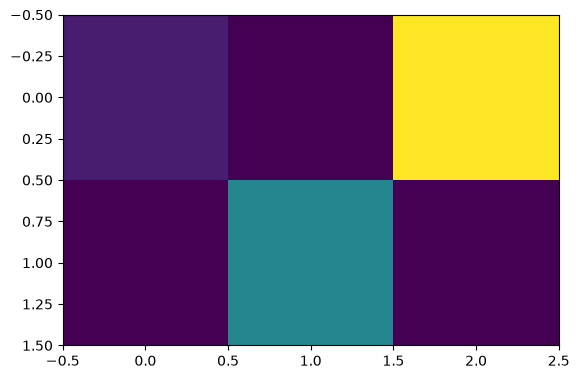

In [21]:
a[0,0]=1
a[1,1]=6
a[0,2]=13
matplotlib.pyplot.imshow(a, interpolation="nearest")

In [2]:
import scipy.special
import numpy
import matplotlib.pyplot

In [52]:
class neuralNetwork:
    def __init__(self, inputnodes, hiddennodes, outputnodes, learningrate):
        self.inodes = inputnodes
        self.hnodes = hiddennodes
        self.onodes = outputnodes

        self.wih = numpy.random.normal(0.0, pow(self.hnodes, -0.5), (self.hnodes, self.inodes))
        self.who = numpy.random.normal(0.0, pow(self.onodes, -0.5), (self.onodes, self.hnodes))

        self.lr = learningrate

        self.activation_function = lambda x: scipy.special.expit(x)
        self.inverse_activation_function = lambda x: scipy.special.expit(x)
        
    def train(self, inputs_list, targets_list):
        inputs = numpy.array(inputs_list, ndmin=2).T
        targets = numpy.array(targets_list, ndmin=2).T

        hidden_inputs = numpy.dot(self.wih, inputs)
        hidden_outputs = self.activation_function(hidden_inputs)

        final_inputs = numpy.dot(self.who, hidden_outputs)
        final_outputs = self.activation_function(final_inputs)

        output_errors = targets - final_outputs
        hidden_errors = numpy.dot(self.who.T, output_errors)

        self.who += self.lr * numpy.dot((output_errors * final_outputs * (1.0 - final_outputs)), numpy.transpose(hidden_outputs))
        self.wih += self.lr * numpy.dot((hidden_errors * hidden_outputs * (1.0 - hidden_outputs)), numpy.transpose(inputs))

    def query(self, inputs_list):
        inputs = numpy.array(inputs_list, ndmin=2).T

        hidden_inputs = numpy.dot(self.wih, inputs)
        hidden_outputs = self.activation_function(hidden_inputs)

        final_inputs = numpy.dot(self.who, hidden_outputs)
        final_outputs = self.activation_function(final_inputs)

        return final_outputs

    def backquery(self, target_list):
        final_outputs = numpy.array(target_list, ndmin=2).T
        
        final_inputs = self.inverse_activation_function(final_outputs)

        hidden_outputs = numpy.dot(self.who.T, final_inputs)
        hidden_outputs -= numpy.min(hidden_outputs)
        hidden_outputs /= numpy.max(hidden_outputs)
        hidden_outputs *= 0.98
        hidden_outputs += 0.01
        
        hidden_inputs = self.inverse_activation_function(hidden_outputs)

        inputs = numpy.dot(self.wih.T, hidden_inputs)
        inputs -= numpy.min(inputs)
        inputs /= numpy.max(inputs)
        inputs *= 0.98
        inputs += 0.01

        return inputs
        

input_nodes = 784
hidden_nodes = 100
output_nodes = 10

learning_rate = 0.1

n = neuralNetwork(input_nodes, hidden_nodes, output_nodes, learning_rate)

training_data_file = open("mnist_data/mnist_train_1000.csv", 'r')
training_data_list = training_data_file.readlines()
training_data_file.close()

epochs = 5

for e in range(epochs):
    for record in training_data_list:
        all_values = record.split(',')
        inputs = (numpy.asarray(all_values[1:], dtype=float) / 255.0 * 0.99) + 0.01
        targets = numpy.zeros(output_nodes) + 0.01
        targets[int(all_values[0])] = 0.99
        n.train(inputs, targets)

In [53]:
test_data_file = open("mnist_data/mnist_test_100.csv", 'r')
test_data_list = test_data_file.readlines()
test_data_file.close()

scorecard = []

for test_data in test_data_list:
    all_values = test_data.split(',')

    image_array = numpy.asarray(all_values[1:], dtype=float).reshape((28,28))
    #matplotlib.pyplot.imshow(image_array, cmap='Greys', interpolation='None')

    correct_label = int(all_values[0])
    output = n.query((numpy.asarray(all_values[1:], dtype=float) / 255.0 * 0.99) + 0.01)
    label =  numpy.argmax(output)

    if(label == correct_label):
        scorecard.append(1)
    else:
        scorecard.append(0)
    

In [54]:
scorecard_array = numpy.asarray(scorecard)
print("perfomance = ", scorecard_array.sum()/scorecard_array.size)

perfomance =  0.88


[0.99 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]


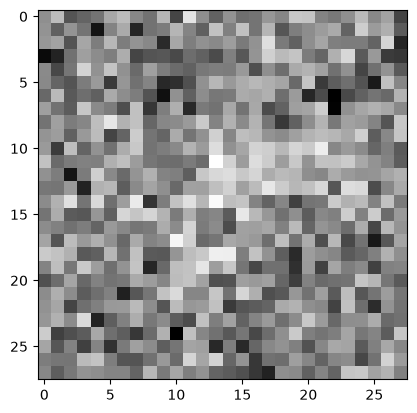

In [55]:
label = 0
targets = numpy.zeros(output_nodes) + 0.01
targets[label] = 0.99
print(targets)

image_data = n.backquery(targets)

matplotlib.pyplot.imshow(image_data.reshape(28,28), cmap='Greys', interpolation='None')